# Machine Learning Homework - Group 22
## Notebook 03 - Feature Selection  (3 pts)

**Objective.** Define and implement a clear feature-selection strategy using methods discussed
in class, and present and justify the final feature set.

**Inputs.** `data/train_clean.csv`, `data/test_clean.csv`, `data/feature_lists.csv`
and `artifacts/features/encoder_categories.csv` (all written by Notebook 02)
**Outputs.** `data/selected_features.csv`, `data/selected_columns.csv`,
`artifacts/features/selection_stages.csv`,
`artifacts/features/selection_scores.csv`, `artifacts/logs/selection_log.csv`,
`artifacts/figures/nb03_selection_funnel.png`, `artifacts/figures/nb03_final_feature_set.png`,
`artifacts/figures/nb03_cv_by_feature_set.png`

### The strategy, and why each stage is here

| # | Stage | Method (taught) | Why this stage exists |
|---|---|---|---|
| 1 | Near-constant filter | `VarianceThreshold` | A column that barely varies cannot separate classes. Notebook 02 left several such flags |
| 2 | Redundancy pruning | `pandas.corr` + the Notebook 01 rule \|r\| >= 0.80 | Notebook 01 found 16 collinear pairs; keeping both members only splits the credit between them |
| 3 | Univariate signal screen | `SelectKBest` with a **custom** score function | Measures each column against the target on its own; the custom scorer is the point-biserial correlation Notebook 01 used |
| 4 | Model-based ranking | `SelectFromModel(DecisionTreeClassifier)` and `RFE(LogisticRegression)` | A univariate screen cannot see interactions (tree) or joint contribution (RFE); both rank, neither is trusted alone |
| 5 | Evidence-based choice | `cross_validate` under `StratifiedKFold` (criterion) and `GroupKFold` (stricter check) | The final set is chosen by measured cross-validated F1, not by taste, and the ranking is shown under both protocols |

**Group-aware decisions.** Notebook 02 one-hot encoded the categoricals, so a single concept
such as `payment_type` is spread over several `cat_*` columns. Dropping one dummy while
keeping its siblings makes the remaining ones mean "everything except that level", which is a
different variable. Selection therefore happens at the level of the **source column**: all
dummies of a concept move through the funnel together. The mapping is read back from
`artifacts/features/encoder_categories.csv`, so it is the encoder's own record, not a guess.

**No re-preprocessing.** Notebook 02 already imputed, log-transformed, scaled and encoded, and its
scaler was fitted on training rows only, so Stage 5 feeds that matrix straight to the reference
model. An earlier version of this notebook re-fitted a `StandardScaler` inside every fold instead;
that step also standardised the 0/1 flags and one-hot dummies, which inflates rare categories (a
level present in 0.5% of rows is divided by a standard deviation of about 0.07), and Notebook 04
measures it as a loss of ROC-AUC. The scaler therefore stays where it was fitted, and only the
model is re-fitted per fold.

**Nothing here touches `test.csv` other than to carry its columns through.** Every selector is
fitted on training rows only, and the final list is written once for Notebook 04.

### Order of operations
1. Setup
2. Load Notebook 02 outputs and verify them
3. Build the candidate pool and the group map
4. Stage 1 - near-constant filter
5. Stage 2 - redundancy pruning
6. Stage 3 - univariate screen
7. Stage 4 - model-based rankings
8. Stage 5 - cross-validated comparison of the candidate sets
9. Choose the final set and justify it
10. Persist the selection and the log
11. Handover to Notebook 04

### Cell 1 - Environment
**Purpose.** Import only the selection tools taught in the course and fix the thresholds used below.
**Look at.** `REDUNDENCY_CUTOFF` comes from Notebook 01 and `UNIVARIATE_CUTOFF` is stated here so the
rule is visible rather than buried.

In [1]:
# CELL 1 - Setup: imports, paths, constants.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.feature_selection import VarianceThreshold, SelectKBest, SelectFromModel, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_validate
from sklearn.metrics import get_scorer

ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
ARTIFACTS_DIR = ROOT / "artifacts"
FIG_DIR = ARTIFACTS_DIR / "figures"
LOG_DIR = ARTIFACTS_DIR / "logs"
FEAT_DIR = ARTIFACTS_DIR / "features"

TARGET = "repeat_purchase_90d"
RANDOM_STATE = 42
PLOT_BLUE = "#1779A8"
PLOT_ORANGE = "#C96A00"

REDUNDENCY_CUTOFF = 0.80   # the rule Notebook 01 established for collinear pairs
UNIVARIATE_CUTOFF = 0.05   # |point-biserial r| below this is indistinguishable from noise here
N_SPLITS = 5               # folds for the Stage 5 comparison (run under two protocols)

SEL_LOG = []


def log_stage(stage, method, before, after, detail):
    SEL_LOG.append({"stage": stage, "method": method, "groups_before": before,
                    "groups_after": after, "detail": detail})


def guide(ax, text):
    # Append a "how to read" caption to the axes title, so a figure still explains itself
    # when it is printed on a page or opened on its own.
    ax.set_title(ax.get_title() + "\n" + text, fontsize=9)

sns.set_theme(style="whitegrid")
print("Environment ready.")
print("  inputs :", DATA_DIR / "train_clean.csv")
print("  outputs:", FEAT_DIR, LOG_DIR, FIG_DIR)

Environment ready.
  inputs : C:\Users\Mohamed_Triki\Desktop\Projets\machine_learning\ML_Group_22\data\train_clean.csv
  outputs: C:\Users\Mohamed_Triki\Desktop\Projets\machine_learning\ML_Group_22\artifacts\features C:\Users\Mohamed_Triki\Desktop\Projets\machine_learning\ML_Group_22\artifacts\logs C:\Users\Mohamed_Triki\Desktop\Projets\machine_learning\ML_Group_22\artifacts\figures


### Cell 2 - Load and verify
**Purpose.** Read Notebook 02's matrices and Notebook 03's own declared pool, and check they agree.
**Method.** The feature list from Notebook 02 is compared with the actual columns; nulls and column
alignment are asserted.
**Look at.** `selected set is a subset of all features` and the customer count - the reason the next
notebook validates by group.

In [2]:
# CELL 2 - Load the matrices Notebook 02 produced and verify them.
train = pd.read_csv(DATA_DIR / "train_clean.csv")
test = pd.read_csv(DATA_DIR / "test_clean.csv")
lists = pd.read_csv(DATA_DIR / "feature_lists.csv")
enc_cats = pd.read_csv(FEAT_DIR / "encoder_categories.csv")

ID_COLS = ["ID", "customer_id"]
y = train[TARGET]

print("=== Shapes ===")
print("  train:", train.shape, "| test:", test.shape)
print("  target positive rate:", round(float(y.mean()), 4))

modelled = lists[lists["kind"].isin(["numeric_scaled", "indicator_flag", "one_hot"])]
print("\n=== Candidate pool declared by Notebook 02 ===")
print(modelled["kind"].value_counts().to_string())
print("  total modelled features:", len(modelled))
print("  excluded by Notebook 02:", lists[lists["kind"].str.startswith("excluded")]["feature"].tolist())

available = [c for c in train.columns if c not in ID_COLS + [TARGET]]
print("\n=== Consistency check ===")
print("  columns in train_clean matching the declared pool:", len([c for c in available if c in set(modelled["feature"])]),
      "of", len(available))
assert set(available) == set(modelled["feature"]), "Notebook 02 and its feature list disagree"
assert train[available].isna().sum().sum() == 0 and test[available].isna().sum().sum() == 0
assert sorted(train[available].columns) == sorted(test[available].columns)
print("  no nulls, train/test columns aligned")

=== Shapes ===
  train: (6469, 127) | test: (986, 126)
  target positive rate: 0.5597

=== Candidate pool declared by Notebook 02 ===
kind
one_hot           82
numeric_scaled    30
indicator_flag    12
  total modelled features: 124
  excluded by Notebook 02: ['purchase_year', 'random_noise', 'municipality', 'city', 'postal_area', 'postal_code', 'street', 'address', 'customer_type', 'company_name']

=== Consistency check ===
  columns in train_clean matching the declared pool: 124 of 124
  no nulls, train/test columns aligned


### Cell 3 - Group map
**Purpose.** Decide at the level of a concept, not of a dummy column.
**Method.** One-hot columns are traced back to their source attribute using Notebook 02's encoder
record, so all dummies of a concept move through the funnel together.
**Look at.** The multi-column groups: dropping one dummy of a concept would silently redefine the
survivors.

In [3]:
# CELL 3 - Build the group map so every one-hot concept is decided as one unit.
# The prefixes come from Notebook 02's own encoder record, not from string guessing.
enc_columns = enc_cats["column"].tolist()

group_of = {}
for col in available:
    if col.startswith("cat_"):
        source = None
        for c in enc_columns:
            if col.startswith("cat_" + c + "_"):
                source = c
                break
        group_of[col] = source if source is not None else col
    else:
        group_of[col] = col

feature_group = pd.Series(group_of)
groups = sorted(set(feature_group.values))
group_members = {g: [c for c in available if feature_group[c] == g] for g in groups}

comp = pd.DataFrame({"group": groups,
                     "n_columns": [len(group_members[g]) for g in groups],
                     "kind": ["one_hot" if g in enc_columns else
                              ("flag" if str(g).startswith("flag_") else "numeric") for g in groups]})
print("=== Groups that selection will decide on ===")
print("  groups:", len(groups), "| columns:", len(available))
print("  composition:")
print(comp["kind"].value_counts().to_string())
print("\n  multi-column groups (one-hot concepts):")
for g in comp[comp["n_columns"] > 1]["group"]:
    print("    {:24s} {:3d} dummies".format(g, len(group_members[g])))
print("\n  single-column groups:", int((comp["n_columns"] == 1).sum()))
assert sum(len(v) for v in group_members.values()) == len(available)


def group_columns(gs, universe):
    # Expand groups back to columns, but never resurrect a column an earlier stage removed.
    return [c for g in gs for c in group_members[g] if c in universe]

=== Groups that selection will decide on ===
  groups: 53 | columns: 124
  composition:
kind
numeric    30
flag       12
one_hot    11

  multi-column groups (one-hot concepts):
    commercial_region         11 dummies
    commercial_zone            2 dummies
    country_or_region          2 dummies
    customer_since_year        9 dummies
    document_series            2 dummies
    island                    10 dummies
    payment_type               5 dummies
    purchase_month            11 dummies
    salesperson                6 dummies
    transport_method          22 dummies
    warehouse                  2 dummies

  single-column groups: 42


### Cell 4 - Stage 1, near-constant filter
**Purpose.** Remove columns that carry almost no variation.
**Method.** `VarianceThreshold` at 0.01 on standardised columns; whole groups are dropped together.
**Look at.** The dropped list: they are mostly rare `Other` dummies and one-off flags.

In [4]:
# CELL 4 - Stage 1: near-constant filter (VarianceThreshold).
# On standardised columns a variance of ~1 is the reference, so a threshold well below 1
# removes columns that are effectively constant. Whole one-hot groups are dropped together.
vt = VarianceThreshold(threshold=0.01)
vt.fit(train[available])
kept_cols = [c for c, k in zip(available, vt.get_support()) if k]
dropped_cols = [c for c, k in zip(available, vt.get_support()) if not k]

var_now = train[available].var()
dropped_groups = sorted({feature_group[c] for c in dropped_cols})
kept_groups = [g for g in groups if g not in dropped_groups]

print("=== Stage 1: VarianceThreshold(threshold=0.01) ===")
print("  columns kept:", len(kept_cols), "of", len(available))
print("  groups kept :", len(kept_groups), "of", len(groups))
print("\n  dropped columns and their variance (train):")
for c in dropped_cols:
    print("    {:46s} var = {:.5f}".format(c, float(var_now[c])))
if not dropped_cols:
    print("    none - every column carries some variation")
assert len(kept_groups) == len(groups) - len(dropped_groups)
log_stage("1 variance", "VarianceThreshold(0.01)", len(groups), len(kept_groups),
          "{} groups dropped: {}".format(len(dropped_groups), ", ".join(dropped_groups) if dropped_groups else "none"))

=== Stage 1: VarianceThreshold(threshold=0.01) ===
  columns kept: 113 of 124
  groups kept : 42 of 53

  dropped columns and their variance (train):
    flag_sentinel_prior_mean_purchase_value        var = 0.00247
    flag_sentinel_spend_365d                       var = 0.00231
    flag_negative_spend_365d                       var = 0.00231
    flag_negative_days_since_previous_purchase     var = 0.00247
    flag_negative_prior_mean_gap_days              var = 0.00247
    cat_salesperson_Other                          var = 0.00797
    cat_commercial_zone_Other                      var = 0.00889
    cat_warehouse_Other                            var = 0.00324
    cat_country_or_region_Other                    var = 0.00293
    cat_island_Other                               var = 0.00154
    cat_customer_since_year_Other                  var = 0.00400


### Cell 5 - Stage 2, redundancy pruning
**Purpose.** Stop carrying the same information twice.
**Method.** Each group is represented by its most target-associated column, groups are correlated,
and the weaker member of any pair at or above |r| 0.80 is dropped - the rule Notebook 01 established.
**Look at.** The pairs table: the monetary totals are one variable in five costumes.

In [5]:
# CELL 5 - Stage 2: redundancy pruning, using the Notebook 01 rule |r| >= 0.80.
# Group-aware: the correlation that matters is between two CONCEPTS, so each group is
# represented by the column with the strongest association to the target, and pairs above the
# cutoff are resolved by dropping the weaker of the two.
pool_cols = [c for c in kept_cols]
X_pool = train[pool_cols]
assoc_pool = pd.Series({c: abs(float(np.corrcoef(X_pool[c], y)[0, 1])) for c in pool_cols})

group_rep = {g: max([c for c in group_members[g] if c in kept_cols], key=lambda c: assoc_pool.get(c, 0.0))
             for g in kept_groups}
rep_names = [group_rep[g] for g in kept_groups]
rep_corr = X_pool[rep_names].corr(numeric_only=True)

pairs = []
for i, ga in enumerate(kept_groups):
    for gb in kept_groups[i + 1:]:
        v = rep_corr.loc[group_rep[ga], group_rep[gb]]
        if pd.notna(v) and abs(v) >= REDUNDENCY_CUTOFF:
            pairs.append({"group_a": ga, "group_b": gb, "r": v,
                          "assoc_a": assoc_pool[group_rep[ga]], "assoc_b": assoc_pool[group_rep[gb]]})
pairs_df = pd.DataFrame(pairs, columns=["group_a", "group_b", "r", "assoc_a", "assoc_b"])
if len(pairs_df):
    pairs_df = pairs_df.sort_values("r", key=abs, ascending=False)

print("=== Stage 2: drop the weaker member of each |r| >= {:.2f} group pair ===".format(REDUNDENCY_CUTOFF))
print(pairs_df.to_string(index=False, float_format=lambda v: "{:.3f}".format(v)) if len(pairs_df) else "  no redundant pairs")

dropped_redun = []
for _, row in pairs_df.iterrows():
    if row["group_a"] in dropped_redun or row["group_b"] in dropped_redun:
        continue
    loser = row["group_b"] if row["assoc_a"] >= row["assoc_b"] else row["group_a"]
    dropped_redun.append(loser)

kept_groups_2 = [g for g in kept_groups if g not in dropped_redun]
kept_cols_2 = group_columns(kept_groups_2, kept_cols)
print("\n  groups dropped for redundancy:", dropped_redun if dropped_redun else "none")
print("  groups kept: {} | columns kept: {}".format(len(kept_groups_2), len(kept_cols_2)))
log_stage("2 redundancy", "pandas.corr on group representatives, |r| >= {:.2f}".format(REDUNDENCY_CUTOFF),
          len(kept_groups), len(kept_groups_2),
          "{} pairs, dropped {}".format(len(pairs_df), dropped_redun if dropped_redun else "none"))

=== Stage 2: drop the weaker member of each |r| >= 0.80 group pair ===
                 group_a                  group_b      r  assoc_a  assoc_b
           Total Liquido            Total a Pagar  1.000    0.036    0.039
             Total Bruto            Total Liquido  0.992    0.063    0.036
             Total Bruto            Total a Pagar  0.991    0.063    0.039
prior_max_purchase_value        prior_total_spend  0.964    0.230    0.275
     prior_mean_gap_days       prior_std_gap_days  0.950    0.003    0.033
        mean_ticket_365d               spend_365d  0.946    0.184    0.302
     purchase_count_180d      purchase_count_365d  0.917    0.407    0.424
     recent_share_30_90d                spend_30d  0.915    0.168    0.234
flag_no_purchase_history prior_max_purchase_value -0.902    0.146    0.230
      purchase_count_30d                spend_30d  0.893    0.278    0.234
     purchase_count_180d       purchase_count_90d  0.882    0.407    0.396
       prior_total_spend     

### Cell 6 - Stage 3, univariate screen
**Purpose.** Drop what says nothing about the target on its own.
**Method.** `SelectKBest` with a custom scorer computing the point-biserial correlation, scored at
group level so a concept is not penalised for being split across dummies.
**Look at.** Every group with its score and its keep decision - nothing is hidden behind a top-k cut.

In [6]:
# CELL 6 - Stage 3: univariate signal screen (SelectKBest with a custom score function).
# For a binary target the point-biserial correlation equals the Pearson correlation, which is
# what Notebook 01 used; computing it with np.corrcoef keeps the same meaning and stays silent
# on constant columns. A group is scored by its strongest dummy, so one concept is not
# penalised for being split across columns.
def abs_pbiserial(X, y):
    X = np.asarray(X, dtype=float)
    yv = np.asarray(y, dtype=float)
    scores = np.zeros(X.shape[1])
    for j in range(X.shape[1]):
        col = X[:, j]
        if col.std() == 0 or yv.std() == 0:
            scores[j] = 0.0
        else:
            scores[j] = abs(float(np.corrcoef(col, yv)[0, 1]))
    pvals = np.ones(X.shape[1])
    return scores, pvals


X_stage2 = train[kept_cols_2]
sk = SelectKBest(score_func=abs_pbiserial, k="all")
sk.fit(X_stage2, y)
col_scores = pd.Series(sk.scores_, index=kept_cols_2)

group_score = pd.Series({g: float(max(col_scores[c] for c in group_members[g] if c in kept_cols_2))
                         for g in kept_groups_2})
group_score = group_score.sort_values(ascending=False)
kept_groups_3 = [g for g in group_score.index if group_score[g] >= UNIVARIATE_CUTOFF]
kept_cols_3 = group_columns(kept_groups_3, kept_cols)

print("=== Stage 3: keep groups whose best |point-biserial r| >= {:.2f} ===".format(UNIVARIATE_CUTOFF))
report = pd.DataFrame({"group": group_score.index,
                       "abs_r": group_score.values,
                       "n_columns": [len(group_members[g]) for g in group_score.index],
                       "kept": [g in kept_groups_3 for g in group_score.index]})
print(report.to_string(index=False, float_format=lambda v: "{:.4f}".format(v)))
print("\n  groups kept: {} of {} | columns kept: {}".format(len(kept_groups_3), len(kept_groups_2), len(kept_cols_3)))
log_stage("3 univariate", "SelectKBest(custom point-biserial), cutoff {:.2f}".format(UNIVARIATE_CUTOFF),
          len(kept_groups_2), len(kept_groups_3),
          "{} groups below cutoff".format(len(kept_groups_2) - len(kept_groups_3)))

=== Stage 3: keep groups whose best |point-biserial r| >= 0.05 ===
                                    group  abs_r  n_columns  kept
                      purchase_count_365d 0.4240          1  True
                       purchase_count_90d 0.3964          1  True
                               spend_180d 0.3170          1  True
                             payment_type 0.2281          5  True
                 prior_std_purchase_value 0.2267          1  True
                        Total Desc_ Linha 0.1931          1  True
                        commercial_region 0.1656         11  True
                 flag_no_purchase_history 0.1462          1  True
                     customer_tenure_days 0.1063          1  True
                     flag_single_purchase 0.1022          1  True
             days_since_previous_purchase 0.1022          1  True
                           purchase_month 0.0968         11  True
                         transport_method 0.0958         22  True
         

### Cell 7 - Stage 4, model-based rankings
**Purpose.** Ask two models what a univariate screen cannot see.
**Method.** `SelectFromModel` on a decision tree finds non-linear structure; `RFE` on a logistic model
asks what a linear model still needs once the strongest columns are taken away. Neither decides alone.
**Look at.** The agreement table: where the two disagree is exactly where judgement is needed.

In [7]:
# CELL 7 - Stage 4: model-based rankings (SelectFromModel on a tree, and RFE on a linear model).
# These two answer different questions: the tree finds non-linear and interaction structure,
# RFE asks what a linear model still needs once the strongest columns are taken away. Neither
# is allowed to decide alone; both are used to build one extra candidate set.
X3 = train[kept_cols_3]

tree_sel = SelectFromModel(DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE))
tree_sel.fit(X3, y)
tree_imp = pd.Series(tree_sel.get_support(), index=kept_cols_3).astype(int)
tree_scores = pd.Series(tree_sel.estimator_.feature_importances_, index=kept_cols_3)

rfe = RFE(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), n_features_to_select=20, step=5)
rfe.fit(X3, y)
rfe_rank = pd.Series(rfe.ranking_, index=kept_cols_3)

tree_groups = sorted({feature_group[c] for c in kept_cols_3 if tree_imp[c] == 1})
rfe_groups = sorted({feature_group[c] for c in kept_cols_3 if rfe_rank[c] <= 20})

print("=== Stage 4a: SelectFromModel(DecisionTreeClassifier) ===")
print("  columns above the mean-importance threshold:", int(tree_imp.sum()), "of", len(kept_cols_3))
print("  groups selected:", len(tree_groups))
print("\n=== Stage 4b: RFE(LogisticRegression, 20 features) ===")
print("  groups selected:", len(rfe_groups))
print("\n  agreement with the Stage 3 survivors:")
print("    in both tree and RFE :", sorted(set(tree_groups) & set(rfe_groups)))
print("    tree only            :", sorted(set(tree_groups) - set(rfe_groups)))
print("    RFE only             :", sorted(set(rfe_groups) - set(tree_groups)))
print("    neither              :", sorted(set(kept_groups_3) - set(tree_groups) - set(rfe_groups)))
log_stage("4 model-based", "SelectFromModel(tree) + RFE(logistic)", len(kept_groups_3),
          len(set(tree_groups) | set(rfe_groups)),
          "tree {} groups, RFE {} groups".format(len(tree_groups), len(rfe_groups)))

=== Stage 4a: SelectFromModel(DecisionTreeClassifier) ===
  columns above the mean-importance threshold: 7 of 64
  groups selected: 7

=== Stage 4b: RFE(LogisticRegression, 20 features) ===
  groups selected: 19

  agreement with the Stage 3 survivors:
    in both tree and RFE : ['Total Bruto', 'Total Desc_ Linha', 'commercial_region', 'customer_tenure_days', 'prior_std_purchase_value', 'purchase_count_365d', 'spend_180d']
    tree only            : []
    RFE only             : ['Total Imp_', 'days_since_previous_purchase', 'flag_imputed_prior_std_gap_days', 'flag_no_purchase_history', 'flag_single_purchase', 'invoice_count_current_purchase', 'payment_type', 'prior_mean_purchase_value', 'prior_min_purchase_value', 'purchase_count_90d', 'purchase_month', 'transport_method']
    neither              : []


### Cell 8 - Stage 5, measured comparison
**Purpose.** Compare candidate feature sets by cross-validated F1 instead of by taste.
**Method.** One reference logistic model, scored twice per candidate set: `StratifiedKFold` (5 folds,
shuffled, seed 42) as the ranking criterion, and `GroupKFold` on `customer_id` as the stricter check.
Both columns are printed and both are drawn in the figure, so a set that only wins under the friendlier
protocol is visible rather than hidden. Duplicate sets are detected and not re-measured.
**Why stratified is the criterion.** It is the course default for a classification split, it keeps the
56/44 class balance inside every fold, and the optimism it allows is bounded and measured: Notebook 04
quantifies it at +0.006 F1 for the same model. The grouped column is kept next to it because a feature
set that cannot survive both is not one worth shipping.
**Look at.** The spread between sets: if it is inside the fold noise, parsimony wins.

In [8]:
# CELL 8 - Stage 5: choose between candidate sets with measured cross-validated F1.
# The Kaggle metric is F1 on hard labels, so that is the scorer used here. Every candidate set is
# scored under both protocols: stratified folds decide, grouped folds verify. Five folds, one
# reference logistic model, identical settings for every candidate set.
candidate_sets = {
    "A all features": groups,
    "B after variance": kept_groups,
    "C + redundancy": kept_groups_2,
    "D + univariate": kept_groups_3,
    "E tree selected": tree_groups,
    "F RFE selected": rfe_groups,
    "G tree or RFE": sorted(set(tree_groups) | set(rfe_groups)),
    "H tree and RFE": sorted(set(tree_groups) & set(rfe_groups)),
}

# Several strategies can converge on the same set; comparing it twice would just repeat a row.
seen, unique_sets, duplicates = {}, {}, []
for name, gs in candidate_sets.items():
    key = frozenset(gs)
    if key in seen:
        duplicates.append("{} == {}".format(name, seen[key]))
        continue
    seen[key] = name
    unique_sets[name] = gs
print("=== Candidate sets compared ({} unique of {} proposed) ===".format(len(unique_sets), len(candidate_sets)))
for d in duplicates:
    print("  duplicate dropped:", d)

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
cv_strict = GroupKFold(n_splits=N_SPLITS)
customer_ids = train["customer_id"].to_numpy()
ref_model = Pipeline([("clf", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))])
scorer = get_scorer("f1")

rows, fold_rows = [], []
for name, gs in unique_sets.items():
    cols = group_columns(gs, kept_cols)
    Xs = train[cols]
    scores = cross_validate(ref_model, Xs, y, cv=cv, scoring=scorer, return_train_score=True)
    strict = cross_validate(ref_model, Xs, y, cv=cv_strict, scoring=scorer, groups=customer_ids)
    rows.append({"feature_set": name, "n_groups": len(gs), "n_columns": len(cols),
                 "cv_f1_mean": scores["test_score"].mean(), "cv_f1_std": scores["test_score"].std(),
                 "cv_f1_grouped": strict["test_score"].mean(),
                 "cv_f1_grouped_std": strict["test_score"].std(),
                 "train_f1_mean": scores["train_score"].mean()})
    for k, s in enumerate(scores["test_score"], start=1):
        fold_rows.append({"feature_set": name, "fold": k, "f1": s})

results = pd.DataFrame(rows).sort_values("cv_f1_mean", ascending=False)
print("=== Stage 5: reference logistic model, scorer = F1, criterion = StratifiedKFold ===")
print(results.to_string(index=False, float_format=lambda v: "{:.4f}".format(v)))
best = results.head(1).to_dict("records")[0]
print("\n  best mean CV F1: {:.4f} ({})".format(best["cv_f1_mean"], best["feature_set"]))
print("  spread across sets: {:.4f}".format(results["cv_f1_mean"].max() - results["cv_f1_mean"].min()))
same = results.sort_values("cv_f1_mean", ascending=False)["feature_set"].tolist()
same_g = results.sort_values("cv_f1_grouped", ascending=False)["feature_set"].tolist()
print("  ranking under StratifiedKFold : {}".format(", ".join(same)))
print("  ranking under GroupKFold      : {}".format(", ".join(same_g)))
if same[0] == same_g[0]:
    print("  the two protocols agree on the same winner.")
else:
    print("  they disagree: the stricter protocol would prefer '{}'. Both columns stay in the table,".format(same_g[0]))
    print("  and the parsimony rule below is applied to the stratified column, so the disagreement")
    print("  is reported rather than resolved by picking the friendlier protocol.")

=== Candidate sets compared (5 unique of 8 proposed) ===
  duplicate dropped: F RFE selected == D + univariate
  duplicate dropped: G tree or RFE == D + univariate
  duplicate dropped: H tree and RFE == E tree selected


=== Stage 5: reference logistic model, scorer = F1, criterion = StratifiedKFold ===
     feature_set  n_groups  n_columns  cv_f1_mean  cv_f1_std  cv_f1_grouped  cv_f1_grouped_std  train_f1_mean
B after variance        42         88      0.7460     0.0086         0.7410             0.0124         0.7561
  A all features        53        113      0.7459     0.0053         0.7476             0.0142         0.7634
  D + univariate        19         64      0.7454     0.0038         0.7389             0.0125         0.7517
  C + redundancy        29         75      0.7439     0.0045         0.7425             0.0096         0.7556
 E tree selected         7         17      0.7317     0.0044         0.7317             0.0126         0.7355

  best mean CV F1: 0.7460 (B after variance)
  spread across sets: 0.0142
  ranking under StratifiedKFold : B after variance, A all features, D + univariate, C + redundancy, E tree selected
  ranking under GroupKFold      : A all features, C + redundancy,

### Cell 9 - Final choice
**Purpose.** Apply the parsimony rule stated in advance and show the resulting set.
**Method.** Among sets within one fold-standard-deviation of the best, take the smallest.
**Look at.** The two figures: the chosen set with its scores, and the CV comparison with whiskers.

=== Final selection ===
  parsimony tolerance (mean fold std): 0.0053
  sets within tolerance of the best  : ['B after variance', 'A all features', 'D + univariate', 'C + redundancy']
  chosen set                           : D + univariate
  groups: 19 | columns: 64 (from 124 candidates)
  mean CV F1 0.7454 (+/- 0.0038) vs full-feature set 0.7459

  composition of the final set:
kind
numeric    12
one_hot     4
flag        3

  selected groups:
    purchase_count_365d          |r| =  0.4240   1 column(s)
    purchase_count_90d           |r| =  0.3964   1 column(s)
    spend_180d                   |r| =  0.3170   1 column(s)
    payment_type                 |r| =  0.2281   5 column(s)
    prior_std_purchase_value     |r| =  0.2267   1 column(s)
    Total Desc_ Linha            |r| =  0.1931   1 column(s)
    commercial_region            |r| =  0.1656   11 column(s)
    flag_no_purchase_history     |r| =  0.1462   1 column(s)
    customer_tenure_days         |r| =  0.1063   1 column(s)
 

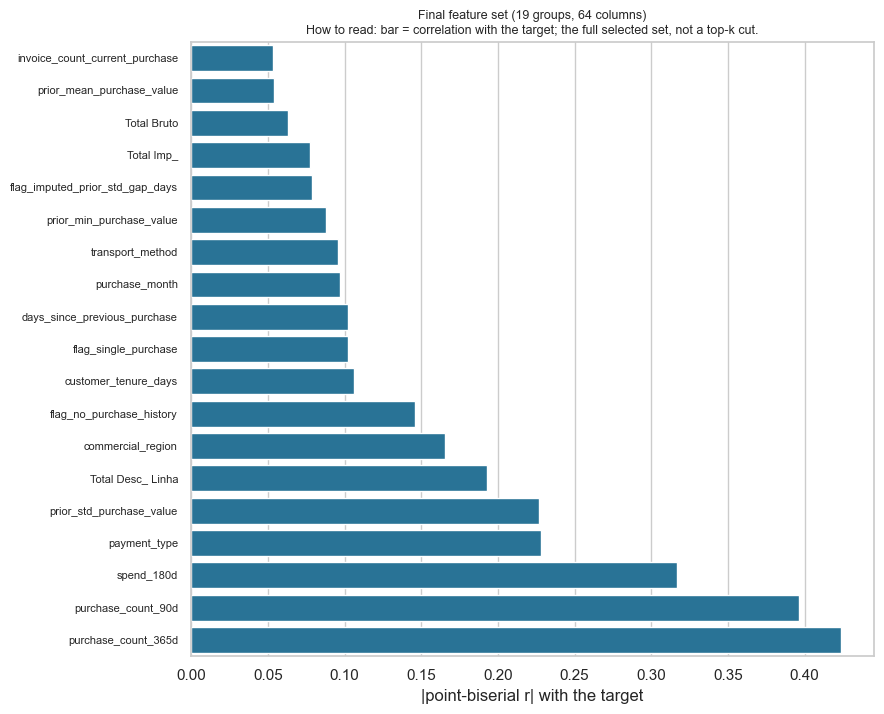

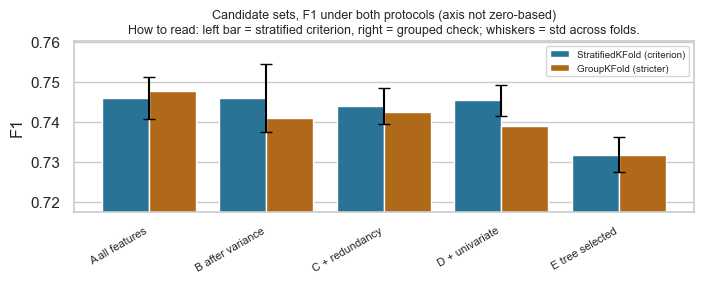

In [9]:
# CELL 9 - Final choice, by a rule stated in advance rather than by taste.
# Rule: among the sets whose mean CV F1 is within one fold-standard-deviation of the best,
# take the smallest. That is the usual parsimony logic - do not carry a feature that buys
# nothing measurable.
tol = results["cv_f1_std"].mean()
competitive = results[results["cv_f1_mean"] >= results["cv_f1_mean"].max() - tol]
final_row = competitive.sort_values(["n_groups", "cv_f1_mean"], ascending=[True, False]).head(1).to_dict("records")[0]
final_groups = candidate_sets[final_row["feature_set"]]
final_cols = group_columns(final_groups, kept_cols)

print("=== Final selection ===")
print("  parsimony tolerance (mean fold std): {:.4f}".format(tol))
print("  sets within tolerance of the best  :", competitive["feature_set"].tolist())
print("  chosen set                           :", final_row["feature_set"])
print("  groups: {} | columns: {} (from {} candidates)".format(
    final_row["n_groups"], final_row["n_columns"], len(available)))
print("  mean CV F1 {:.4f} (+/- {:.4f}) vs full-feature set {:.4f}".format(
    final_row["cv_f1_mean"], final_row["cv_f1_std"],
    float(results[results["feature_set"] == "A all features"]["cv_f1_mean"].tolist()[0])))

final_group_cols = {g: [c for c in group_members[g] if c in kept_cols] for g in final_groups}
comp_final = pd.DataFrame({"group": final_groups,
                           "kind": ["one_hot" if g in enc_columns else
                                    ("flag" if str(g).startswith("flag_") else "numeric") for g in final_groups],
                           "n_columns": [len(final_group_cols[g]) for g in final_groups]})
print("\n  composition of the final set:")
print(comp_final["kind"].value_counts().to_string())
print("\n  selected groups:")
for g in sorted(final_groups, key=lambda x: -float(group_score.get(x, 0))):
    print("    {:28s} |r| = {:>7}   {} column(s)".format(
        g, "{:.4f}".format(float(group_score.get(g, float("nan")))), len(final_group_cols[g])))

fig, ax = plt.subplots(figsize=(9, 1.6 + 0.30 * len(final_groups)))
sel_scores = pd.DataFrame({"group": [g for g in final_groups],
                           "abs_r": [float(group_score.get(g, 0.0)) for g in final_groups]}
                          ).sort_values("abs_r")
sns.barplot(data=sel_scores, y="group", x="abs_r", orient="h", color=PLOT_BLUE, ax=ax)
ax.set_title("Final feature set ({} groups, {} columns)".format(len(final_groups), len(final_cols)))
ax.set_xlabel("|point-biserial r| with the target")
ax.set_ylabel("")
plt.setp(ax.get_yticklabels(), fontsize=8)
guide(ax, "How to read: bar = correlation with the target; the full selected set, not a top-k cut.")
plt.tight_layout()
plt.savefig(FIG_DIR / "nb03_final_feature_set.png", dpi=200)
plt.show()
fig, ax = plt.subplots(figsize=(7.2, 3.0))   # print width: the PDF places this 1:1
order = list(unique_sets)
plot_df = results.set_index("feature_set").loc[order].reset_index()
long_df = pd.concat([
    plot_df[["feature_set", "cv_f1_mean", "cv_f1_std"]].rename(
        columns={"cv_f1_mean": "f1", "cv_f1_std": "std"}).assign(protocol="StratifiedKFold (criterion)"),
    plot_df[["feature_set", "cv_f1_grouped", "cv_f1_grouped_std"]].rename(
        columns={"cv_f1_grouped": "f1", "cv_f1_grouped_std": "std"}).assign(protocol="GroupKFold (stricter)"),
], ignore_index=True)
sns.barplot(data=long_df, x="feature_set", y="f1", hue="protocol",
              palette=[PLOT_BLUE, PLOT_ORANGE], ax=ax)
# whiskers = spread across folds; stripplot is not in the course toolkit, errorbar is
strat = long_df[long_df["protocol"].str.startswith("Stratified")]
plt.errorbar(x=[order.index(f) for f in strat["feature_set"]], y=strat["f1"], yerr=strat["std"],
             color="black", marker="none", linestyle="none", capsize=4)
# The differences between sets are ~0.015 F1, invisible from a zero baseline: the axis is
# zoomed to the range of interest and the title says so, which is the honest way to show it.
axis_pad = max(float(plot_df["cv_f1_mean"].max() - plot_df["cv_f1_mean"].min()),
               float(plot_df["cv_f1_std"].mean()))
ax.set_ylim(float(plot_df["cv_f1_mean"].min()) - axis_pad, float(plot_df["cv_f1_mean"].max()) + axis_pad)
ax.set_title("Candidate sets, F1 under both protocols (axis not zero-based)")
ax.set_xlabel("")
ax.set_ylabel("F1")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right", fontsize=8)
ax.legend(loc="upper right", fontsize=7)
guide(ax, "How to read: left bar = stratified criterion, right = grouped check;"
      " whiskers = std across folds.")
plt.tight_layout()
plt.savefig(FIG_DIR / "nb03_cv_by_feature_set.png", dpi=200)
plt.show()

### Cell 10 - Persist
**Purpose.** Write the decision so Notebook 04 reads it instead of re-deciding.
**Look at.** `selected_columns.csv` is the machine-readable handover; the funnel figure shows how many
groups and columns survived each stage.

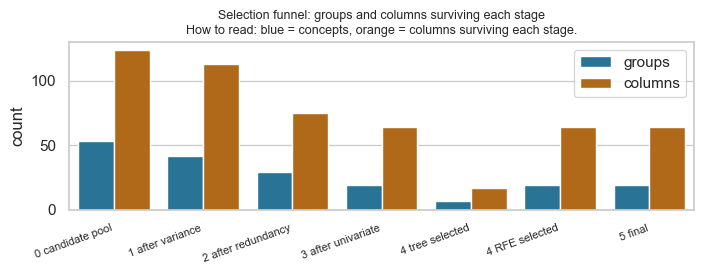

=== Selection funnel ===
             stage  groups  columns
  0 candidate pool      53      124
  1 after variance      42      113
2 after redundancy      29       75
3 after univariate      19       64
   4 tree selected       7       17
    4 RFE selected      19       64
           5 final      19       64

=== Log ===
        stage                                            method  groups_before  groups_after
   1 variance                           VarianceThreshold(0.01)             53            42
 2 redundancy pandas.corr on group representatives, |r| >= 0.80             42            29
 3 univariate   SelectKBest(custom point-biserial), cutoff 0.05             29            19
4 model-based             SelectFromModel(tree) + RFE(logistic)             19            19

Saved: data/selected_features.csv, artifacts/features/selection_stages.csv,
       selection_scores.csv, selection_cv_results.csv, artifacts/logs/selection_log.csv


In [10]:
# CELL 10 - Persist the selection so Notebook 04 reads it instead of re-deciding.
# The column list written here is the set Notebook 04 must use: group members that an earlier
# stage already removed are not resurrected.
pd.DataFrame({"group": final_groups,
              "columns": [", ".join(final_group_cols[g]) for g in final_groups],
              "n_columns": [len(final_group_cols[g]) for g in final_groups],
              "abs_r": [float(group_score.get(g, 0.0)) for g in final_groups]}
             ).to_csv(DATA_DIR / "selected_features.csv", index=False)

# Long form: one row per column, so Notebook 04 never has to re-parse the joined string above.
pd.DataFrame([{"group": g, "column": c, "abs_r": float(group_score.get(g, 0.0))}
              for g in final_groups for c in final_group_cols[g]]
             ).to_csv(DATA_DIR / "selected_columns.csv", index=False)

stages = pd.DataFrame([
    {"stage": "0 candidate pool", "groups": len(groups), "columns": len(available)},
    {"stage": "1 after variance", "groups": len(kept_groups), "columns": len(kept_cols)},
    {"stage": "2 after redundancy", "groups": len(kept_groups_2), "columns": len(kept_cols_2)},
    {"stage": "3 after univariate", "groups": len(kept_groups_3), "columns": len(kept_cols_3)},
    {"stage": "4 tree selected", "groups": len(tree_groups),
     "columns": len(group_columns(tree_groups, kept_cols))},
    {"stage": "4 RFE selected", "groups": len(rfe_groups),
     "columns": len(group_columns(rfe_groups, kept_cols))},
    {"stage": "5 final", "groups": len(final_groups), "columns": len(final_cols)},
])
stages.to_csv(FEAT_DIR / "selection_stages.csv", index=False)

funnel_long = pd.concat([
    stages[["stage", "groups"]].rename(columns={"groups": "count"}).assign(metric="groups"),
    stages[["stage", "columns"]].rename(columns={"columns": "count"}).assign(metric="columns"),
], ignore_index=True)
fig, ax = plt.subplots(figsize=(7.2, 2.9))   # print width: the PDF places this 1:1
sns.barplot(data=funnel_long, x="stage", y="count", hue="metric", orient="v",
            palette=[PLOT_BLUE, PLOT_ORANGE], ax=ax)
ax.set_title("Selection funnel: groups and columns surviving each stage")
ax.set_xlabel("")
ax.set_ylabel("count")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right", fontsize=8)
ax.legend()
guide(ax, "How to read: blue = concepts, orange = columns surviving each stage.")
plt.tight_layout()
plt.savefig(FIG_DIR / "nb03_selection_funnel.png", dpi=200)
plt.show()
pd.DataFrame({"column": col_scores.index, "abs_pointbiserial_r": col_scores.values}
             ).to_csv(FEAT_DIR / "selection_scores.csv", index=False)
results.to_csv(FEAT_DIR / "selection_cv_results.csv", index=False)

log_df = pd.DataFrame(SEL_LOG)
log_df.to_csv(LOG_DIR / "selection_log.csv", index=False)

print("=== Selection funnel ===")
print(stages.to_string(index=False))
print("\n=== Log ===")
print(log_df[["stage", "method", "groups_before", "groups_after"]].to_string(index=False))
print("\nSaved: data/selected_features.csv, artifacts/features/selection_stages.csv,")
print("       selection_scores.csv, selection_cv_results.csv, artifacts/logs/selection_log.csv")

### Cell 11 - Handover
**Purpose.** State what Notebook 04 receives and what it must do next.
**Look at.** The reference F1 and the always-majority baseline, so the gain from modelling is visible
before Notebook 04 starts.

In [11]:
# CELL 11 - Handover to Notebook 04.
print("=== Notebook 03 complete ===")
print("  candidate groups / columns : {} / {}".format(len(groups), len(available)))
print("  final groups / columns     : {} / {}".format(len(final_groups), len(final_cols)))
print("  reference CV F1 on the set : {:.4f} (+/- {:.4f})".format(
    float(final_row["cv_f1_mean"]), float(final_row["cv_f1_std"])))
print("  majority-class baseline    : {:.4f}  (F1 of always predicting the positive class)".format(
    2 * float(y.mean()) / (1 + float(y.mean()))))
print("\nNotebook 04 receives data/train_clean.csv, data/test_clean.csv and")
print("data/selected_features.csv, then trains and assesses the model, tunes the decision")
print("threshold for F1, and writes the Kaggle submission.")

=== Notebook 03 complete ===
  candidate groups / columns : 53 / 124
  final groups / columns     : 19 / 64
  reference CV F1 on the set : 0.7454 (+/- 0.0038)
  majority-class baseline    : 0.7177  (F1 of always predicting the positive class)

Notebook 04 receives data/train_clean.csv, data/test_clean.csv and
data/selected_features.csv, then trains and assesses the model, tunes the decision
threshold for F1, and writes the Kaggle submission.


---

## Where this notebook leaves the project

**Produced.** `data/selected_columns.csv` (the machine-readable selection), `data/selected_features.csv`
(the same grouped by concept), the CV comparison and scores in `artifacts/features/`, and the
stage-by-stage log in `artifacts/logs/selection_log.csv`.

**The strategy in one line.** Near-constant filter, then redundancy pruning at the Notebook 01
threshold, then a univariate screen, then two model-based rankings, and finally a choice between
candidate sets made by cross-validated F1 under a stated parsimony rule.

**Next: Notebook 04 - Model & Assessment.** It compares the selected set against the full set under
a stricter validation protocol, tunes the decision threshold for F1, fits the final model, and
writes the Kaggle submission. Note that Notebook 04 may legitimately use a different set than the
one chosen here - the reason is stated in its opening section.